# Inverse Parameter Estimation and Robustness Analysis

The previous experiments assumed that the thermal diffusivity of the material was known:

$$
\alpha = 1.0\times10^{-4}\;m^2/s
$$

In many real physical systems, however, material parameters are not known exactly and must be estimated from measurements.

This notebook extends the Physics-Informed Neural Network to an inverse problem.

Instead of supplying the thermal diffusivity to the model, $\alpha$ is treated as an unknown trainable parameter.

The PINN must therefore learn both:

$$
T(x,t)
$$

and:

$$
\alpha
$$

from sparse temperature measurements while still satisfying the governing heat equation.

A later robustness experiment will investigate how the reconstruction behaves when sensor information becomes more limited or noisy.

## 1. Loading the Experimental Data

The same sparse, noisy, and incomplete sensor measurements used in the previous experiments are retained.

The complete numerical temperature field is loaded only for final evaluation.

The true thermal diffusivity used to generate the synthetic system is not supplied to the inverse PINN during training.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

import copy

torch.manual_seed(42)
np.random.seed(42)

In [2]:
sensor_df = pd.read_csv(
    "../data/thermal_sensor_data.csv"
)

reference_data = np.load(
    "../data/reference_temperature_field.npz"
)

x_full = reference_data["x"]
time_full = reference_data["time"]
T_true_full = reference_data["temperature_field"]

print("Reference field shape:", T_true_full.shape)

Reference field shape: (286, 81)


## 2. Preparing the Sensor Observations

The available sensor measurements are converted into individual space-time observations:

$$
(x,t,T)
$$

Missing measurements are removed.

The resulting observations will provide the data constraint for the inverse PINN.

In [3]:
sensor_positions = {
    "sensor_0.20m": 0.20,
    "sensor_0.35m": 0.35,
    "sensor_0.50m": 0.50,
    "sensor_0.65m": 0.65,
    "sensor_0.80m": 0.80
}

training_rows = []

for sensor_name, position in sensor_positions.items():

    for row_index in range(len(sensor_df)):

        time_value = sensor_df.loc[
            row_index,
            "time_s"
        ]

        temperature_value = sensor_df.loc[
            row_index,
            sensor_name
        ]

        if not pd.isna(temperature_value):

            training_rows.append(
                [
                    position,
                    time_value,
                    temperature_value
                ]
            )

training_df = pd.DataFrame(
    training_rows,
    columns=[
        "x",
        "time_s",
        "temperature_C"
    ]
)

print(
    "Available observations:",
    len(training_df)
)

Available observations: 1351


## 3. Data Normalization

The spatial coordinate, time, and temperature are normalized using the same scaling strategy as the previous neural-network experiments.

Using the same representation keeps the inverse problem consistent with the earlier baseline and PINN models.

In [4]:
x_min = 0.0
x_max = 1.0

t_min = training_df["time_s"].min()
t_max = training_df["time_s"].max()

T_min = training_df["temperature_C"].min()
T_max = training_df["temperature_C"].max()

x_scale = x_max - x_min
t_scale = t_max - t_min
T_scale = T_max - T_min

In [5]:
training_df["x_norm"] = (
    training_df["x"] - x_min
) / x_scale

training_df["time_norm"] = (
    training_df["time_s"] - t_min
) / t_scale

training_df["temperature_norm"] = (
    training_df["temperature_C"] - T_min
) / T_scale

In [6]:
X_data = torch.tensor(
    training_df[
        ["x_norm", "time_norm"]
    ].values,
    dtype=torch.float32
)

y_data = torch.tensor(
    training_df[
        ["temperature_norm"]
    ].values,
    dtype=torch.float32
)

print(X_data.shape)
print(y_data.shape)

torch.Size([1351, 2])
torch.Size([1351, 1])


## 4. Thermal Diffusivity as an Unknown Parameter

The heat equation is:

$$
\frac{\partial T}{\partial t}
=
\alpha
\frac{\partial^2T}{\partial x^2}
$$

In the previous PINN experiment, $\alpha$ was supplied as a known physical constant.

For the inverse problem, $\alpha$ is instead treated as a trainable model parameter.

The network therefore learns:

$$
T_\theta(x,t)
$$

while simultaneously estimating:

$$
\alpha
$$

from the observed temperature evolution.

Because thermal diffusivity must be positive, the model will optimize a logarithmic parameter:

$$
\eta=\log(\alpha)
$$

and recover the physical diffusivity using:

$$
\alpha=e^\eta
$$

This guarantees that the estimated diffusivity remains positive during training.

In [7]:
initial_alpha_guess = 5.0e-5

log_alpha = nn.Parameter(
    torch.tensor(
        np.log(initial_alpha_guess),
        dtype=torch.float32
    )
)

print(
    "Initial alpha estimate:",
    torch.exp(log_alpha).item()
)

Initial alpha estimate: 5.0000016926787794e-05


## 5. Inverse PINN Architecture

The inverse PINN uses the same neural-network architecture as the previous models.

The network approximates the normalized temperature field:

$$
T_\theta^*(x^*,t^*)
$$

while the thermal diffusivity is treated as an additional trainable physical parameter.

The neural-network weights and the diffusivity estimate are therefore optimized simultaneously during training.

In [8]:
class InversePINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 1)
        )

    def forward(self, inputs):
        return self.network(inputs)

In [9]:
torch.manual_seed(42)

inverse_pinn = InversePINN()

print(inverse_pinn)

InversePINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 6. Physics Residual with Unknown Thermal Diffusivity

The normalized heat-equation residual is:

$$
f
=
\frac{\partial T^*}{\partial t^*}
-
\alpha^*
\frac{\partial^2T^*}{\partial x^{*2}}
$$

where:

$$
\alpha^*
=
\frac{\alpha\Delta t}{\Delta x^2}
$$

Unlike the previous PINN, $\alpha$ is not fixed.

During training, the physical diffusivity is recovered from the trainable logarithmic parameter:

$$
\alpha=e^{\eta}
$$

The current estimate of $\alpha$ is then converted into normalized form and used inside the physics residual.

Gradients therefore propagate not only through the neural-network weights but also through the thermal diffusivity estimate.

In [10]:
def inverse_physics_residual(
    model,
    X_physics,
    log_alpha,
    t_scale,
    x_scale
):

    X = (
        X_physics
        .clone()
        .detach()
        .requires_grad_(True)
    )

    T_pred = model(X)

    first_derivatives = torch.autograd.grad(
        T_pred,
        X,
        grad_outputs=torch.ones_like(T_pred),
        create_graph=True
    )[0]

    dT_dx = first_derivatives[:, 0:1]
    dT_dt = first_derivatives[:, 1:2]

    second_derivatives = torch.autograd.grad(
        dT_dx,
        X,
        grad_outputs=torch.ones_like(dT_dx),
        create_graph=True
    )[0]

    d2T_dx2 = second_derivatives[:, 0:1]

    alpha_physical = torch.exp(
        log_alpha
    )

    alpha_normalized = (
        alpha_physical
        * t_scale
        / x_scale**2
    )

    residual = (
        dT_dt
        -
        alpha_normalized * d2T_dx2
    )

    return residual

In [11]:
num_collocation = 5000

x_physics = torch.rand(
    num_collocation,
    1
)

t_physics = torch.rand(
    num_collocation,
    1
)

X_physics = torch.cat(
    [x_physics, t_physics],
    dim=1
)

print(
    "Physics points:",
    X_physics.shape
)

Physics points: torch.Size([5000, 2])


In [12]:
residual_test = inverse_physics_residual(
    inverse_pinn,
    X_physics,
    log_alpha,
    t_scale,
    x_scale
)

print(
    "Residual shape:",
    residual_test.shape
)

print(
    "Current alpha:",
    torch.exp(log_alpha).item()
)

print(
    "Initial physics loss:",
    torch.mean(
        residual_test**2
    ).item()
)

Residual shape: torch.Size([5000, 1])
Current alpha: 5.0000016926787794e-05
Initial physics loss: 0.002828789409250021


## 8. Train and Validation Sensor Data

The available temperature measurements are divided into training and validation sets.

The training measurements contribute to the inverse PINN data loss, while the validation measurements are used only to monitor generalization during training.

In [13]:
torch.manual_seed(42)

num_samples = X_data.shape[0]

indices = torch.randperm(num_samples)

train_size = int(0.8 * num_samples)

train_indices = indices[:train_size]
val_indices = indices[train_size:]

X_train = X_data[train_indices]
y_train = y_data[train_indices]

X_val = X_data[val_indices]
y_val = y_data[val_indices]

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))

Training observations: 1080
Validation observations: 271


## 9. Boundary Conditions

The two ends of the rod remain fixed at:

$$
20^\circ C
$$

throughout the experiment.

These known boundary conditions are retained in the inverse problem while the thermal diffusivity is treated as unknown.

In [14]:
num_boundary = 500

t_boundary = torch.rand(
    num_boundary,
    1
)

x_left = torch.zeros(
    num_boundary,
    1
)

x_right = torch.ones(
    num_boundary,
    1
)

X_left = torch.cat(
    [x_left, t_boundary],
    dim=1
)

X_right = torch.cat(
    [x_right, t_boundary],
    dim=1
)

In [15]:
boundary_temperature_C = 20.0

boundary_temperature_norm = (
    boundary_temperature_C - T_min
) / T_scale

T_boundary = torch.full(
    (num_boundary, 1),
    float(boundary_temperature_norm),
    dtype=torch.float32
)

## 10. Initial Condition

The initial temperature distribution is assumed to be known.

At:

$$
t=0
$$

the temperature field follows the Gaussian profile used in the original thermal simulation.

The inverse PINN therefore estimates the unknown thermal diffusivity from the subsequent temperature evolution rather than attempting to infer the initial state itself.

In [16]:
num_initial = 200

x_initial = torch.linspace(
    x_min,
    x_max,
    num_initial
).reshape(-1, 1)

t_initial = torch.zeros(
    num_initial,
    1
)

x_initial_norm = (
    x_initial - x_min
) / x_scale

t_initial_norm = (
    t_initial - t_min
) / t_scale

X_initial = torch.cat(
    [x_initial_norm, t_initial_norm],
    dim=1
)

In [17]:
T_initial_C = (
    20.0
    +
    80.0
    * torch.exp(
        -((x_initial - 0.5)**2)
        / (2 * 0.08**2)
    )
)

T_initial_C[0] = 20.0
T_initial_C[-1] = 20.0

T_initial_norm = (
    T_initial_C - T_min
) / T_scale

## 11. Inverse PINN Optimization

The inverse PINN minimizes the same physical and data constraints used by the forward PINN:

$$
\mathcal{L}_{total}
=
\mathcal{L}_{data}
+
\mathcal{L}_{physics}
+
\mathcal{L}_{boundary}
+
\mathcal{L}_{initial}
$$

However, the optimizer now updates both:

- the neural-network weights and biases,
- the logarithmic thermal-diffusivity parameter.

The estimated physical diffusivity is recovered during training using:

$$
\alpha=e^{\eta}
$$

where $\eta$ is the trainable logarithmic parameter.

In [18]:
lambda_physics = 1.0
lambda_boundary = 1.0
lambda_initial = 1.0

loss_function = nn.MSELoss()

In [19]:
optimizer = torch.optim.Adam(
    list(inverse_pinn.parameters())
    + [log_alpha],
    lr=0.001
)

optimizer.step()

In [20]:
max_epochs = 5000

total_loss_history = []
data_loss_history = []
physics_loss_history = []
boundary_loss_history = []
initial_loss_history = []
val_loss_history = []

alpha_history = []

In [21]:
for epoch in range(max_epochs):

    inverse_pinn.train()

    # -------------------------
    # Sensor data loss
    # -------------------------

    T_data_pred = inverse_pinn(
        X_train
    )

    data_loss = loss_function(
        T_data_pred,
        y_train
    )


    # -------------------------
    # Physics loss
    # -------------------------

    residual = inverse_physics_residual(
        inverse_pinn,
        X_physics,
        log_alpha,
        t_scale,
        x_scale
    )

    physics_loss = torch.mean(
        residual**2
    )


    # -------------------------
    # Boundary loss
    # -------------------------

    T_left_pred = inverse_pinn(
        X_left
    )

    T_right_pred = inverse_pinn(
        X_right
    )

    boundary_loss = (
        loss_function(
            T_left_pred,
            T_boundary
        )
        +
        loss_function(
            T_right_pred,
            T_boundary
        )
    ) / 2


    # -------------------------
    # Initial-condition loss
    # -------------------------

    T_initial_pred = inverse_pinn(
        X_initial
    )

    initial_loss = loss_function(
        T_initial_pred,
        T_initial_norm
    )


    # -------------------------
    # Total loss
    # -------------------------

    total_loss = (
        data_loss
        +
        lambda_physics * physics_loss
        +
        lambda_boundary * boundary_loss
        +
        lambda_initial * initial_loss
    )


    # -------------------------
    # Backpropagation
    # -------------------------

    optimizer.zero_grad()

    total_loss.backward()

    optimizer.step()


    # -------------------------
    # Validation
    # -------------------------

    inverse_pinn.eval()

    with torch.no_grad():

        T_val_pred = inverse_pinn(
            X_val
        )

        val_loss = loss_function(
            T_val_pred,
            y_val
        )


    # -------------------------
    # Store histories
    # -------------------------

    total_loss_history.append(
        total_loss.item()
    )

    data_loss_history.append(
        data_loss.item()
    )

    physics_loss_history.append(
        physics_loss.item()
    )

    boundary_loss_history.append(
        boundary_loss.item()
    )

    initial_loss_history.append(
        initial_loss.item()
    )

    val_loss_history.append(
        val_loss.item()
    )

    current_alpha = torch.exp(
        log_alpha
    ).item()

    alpha_history.append(
        current_alpha
    )


    # -------------------------
    # Print progress
    # -------------------------

    if (epoch + 1) % 500 == 0:

        print(
            f"Epoch {epoch + 1} | "
            f"Total: {total_loss.item():.6f} | "
            f"Physics: {physics_loss.item():.6f} | "
            f"Val: {val_loss.item():.6f} | "
            f"Alpha: {current_alpha:.8f}"
        )

Epoch 500 | Total: 0.005677 | Physics: 0.001424 | Val: 0.001979 | Alpha: 0.00004350
Epoch 1000 | Total: 0.001398 | Physics: 0.000513 | Val: 0.000549 | Alpha: 0.00007046
Epoch 1500 | Total: 0.000394 | Physics: 0.000191 | Val: 0.000119 | Alpha: 0.00008835
Epoch 2000 | Total: 0.000193 | Physics: 0.000095 | Val: 0.000056 | Alpha: 0.00009496
Epoch 2500 | Total: 0.000129 | Physics: 0.000056 | Val: 0.000045 | Alpha: 0.00009735
Epoch 3000 | Total: 0.000104 | Physics: 0.000039 | Val: 0.000042 | Alpha: 0.00009836
Epoch 3500 | Total: 0.000096 | Physics: 0.000030 | Val: 0.000044 | Alpha: 0.00009876
Epoch 4000 | Total: 0.000193 | Physics: 0.000028 | Val: 0.000042 | Alpha: 0.00009912
Epoch 4500 | Total: 0.000079 | Physics: 0.000020 | Val: 0.000041 | Alpha: 0.00009930
Epoch 5000 | Total: 0.000081 | Physics: 0.000021 | Val: 0.000042 | Alpha: 0.00009928


## 12. Thermal Diffusivity Identification

The evolution of the estimated thermal diffusivity is examined throughout training.

The inverse PINN was initialized with:

$$
\alpha_{\text{initial}}
=
5.0\times10^{-5}\;m^2/s
$$

while the synthetic reference system was generated using:

$$
\alpha_{\text{true}}
=
1.0\times10^{-4}\;m^2/s
$$

The true value is used only after training for evaluation and was not supplied to the inverse PINN during optimization.

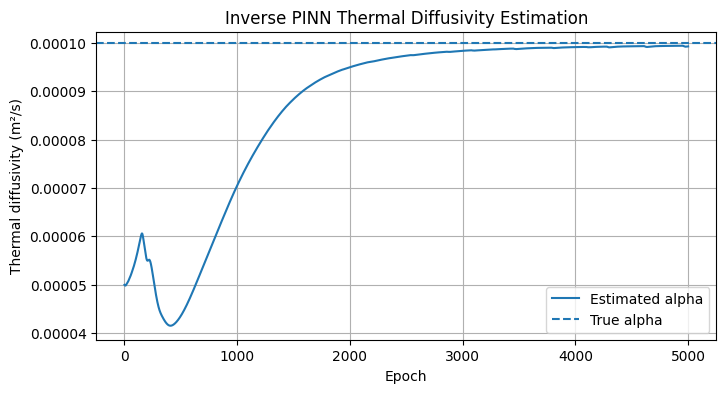

In [22]:
true_alpha = 1.0e-4

plt.figure(figsize=(8, 4))

plt.plot(
    alpha_history,
    label="Estimated alpha"
)

plt.axhline(
    true_alpha,
    linestyle="--",
    label="True alpha"
)

plt.xlabel("Epoch")
plt.ylabel("Thermal diffusivity (m²/s)")
plt.title("Inverse PINN Thermal Diffusivity Estimation")

plt.legend()
plt.grid()

plt.show()

In [23]:
estimated_alpha = torch.exp(
    log_alpha
).item()

alpha_absolute_error = abs(
    estimated_alpha - true_alpha
)

alpha_relative_error = (
    alpha_absolute_error
    / true_alpha
    * 100
)

print(
    f"True alpha: {true_alpha:.8f} m²/s"
)

print(
    f"Estimated alpha: {estimated_alpha:.8f} m²/s"
)

print(
    f"Absolute error: {alpha_absolute_error:.8e} m²/s"
)

print(
    f"Relative error: {alpha_relative_error:.2f}%"
)

True alpha: 0.00010000 m²/s
Estimated alpha: 0.00009928 m²/s
Absolute error: 7.23036262e-07 m²/s
Relative error: 0.72%


### Parameter Estimation Result

The inverse PINN was initialized with a deliberately inaccurate thermal diffusivity:

$$
\alpha_{\text{initial}}
=
5.0\times10^{-5}\;m^2/s
$$

During the early stages of training, the estimated parameter temporarily moved away from the true value as the neural-network weights and physical parameter were optimized simultaneously.

As training progressed, the estimated diffusivity converged toward the value used to generate the synthetic thermal system.

The final estimate was:

$$
\alpha_{\text{estimated}}
=
9.928\times10^{-5}\;m^2/s
$$

compared with the reference value:

$$
\alpha_{\text{true}}
=
1.0\times10^{-4}\;m^2/s
$$

corresponding to a relative parameter-estimation error of approximately:

$$
0.72\%
$$

This demonstrates that the inverse PINN was able to recover an unknown physical parameter from sparse, noisy, and incomplete temperature measurements while simultaneously learning the temperature field.

## 13. Full-Field Reconstruction with the Inverse PINN

After estimating the thermal diffusivity, the inverse PINN is evaluated across the complete space-time domain.

This verifies whether the model simultaneously recovered the unknown physical parameter and reconstructed the underlying temperature field.

In [24]:
x_grid, time_grid = np.meshgrid(
    x_full,
    time_full
)

x_flat = x_grid.reshape(-1, 1)
time_flat = time_grid.reshape(-1, 1)

In [25]:
x_flat_norm = (
    x_flat - x_min
) / x_scale

time_flat_norm = (
    time_flat - t_min
) / t_scale

full_inputs = np.hstack(
    [
        x_flat_norm,
        time_flat_norm
    ]
)

full_inputs_tensor = torch.tensor(
    full_inputs,
    dtype=torch.float32
)

In [26]:
inverse_pinn.eval()

with torch.no_grad():

    inverse_predictions_norm = inverse_pinn(
        full_inputs_tensor
    ).numpy()

In [27]:
inverse_predictions_C = (
    inverse_predictions_norm
    * T_scale
    + T_min
)

T_inverse_full = inverse_predictions_C.reshape(
    len(time_full),
    len(x_full)
)

print(
    "Inverse PINN field shape:",
    T_inverse_full.shape
)

print(
    "True field shape:",
    T_true_full.shape
)

Inverse PINN field shape: (286, 81)
True field shape: (286, 81)


In [28]:
inverse_error_field = (
    T_inverse_full - T_true_full
)

inverse_rmse = np.sqrt(
    np.mean(
        inverse_error_field**2
    )
)

inverse_mae = np.mean(
    np.abs(
        inverse_error_field
    )
)

print(
    f"Inverse PINN Full-field RMSE: "
    f"{inverse_rmse:.4f} °C"
)

print(
    f"Inverse PINN Full-field MAE: "
    f"{inverse_mae:.4f} °C"
)

Inverse PINN Full-field RMSE: 0.1695 °C
Inverse PINN Full-field MAE: 0.1337 °C


### Inverse Reconstruction Result

The inverse PINN achieved a full-field reconstruction error of:

$$
RMSE = 0.1695^\circ C
$$

and:

$$
MAE = 0.1337^\circ C
$$

while simultaneously estimating the unknown thermal diffusivity with a relative error of approximately:

$$
0.72\%
$$

The reconstruction error is slightly higher than that of the forward PINN, which was supplied with the exact thermal diffusivity.

This is expected because the inverse PINN must simultaneously learn the temperature field and identify the unknown physical parameter.

Despite this additional difficulty, the inverse PINN reconstructs the temperature field substantially more accurately than the purely data-driven baseline model.

The result demonstrates that sparse and noisy temperature measurements, together with the governing physical equation, can be used not only for state reconstruction but also for physical parameter identification.

# Part B — Robustness to Sensor Sparsity

## 14. Experimental Design

The previous experiments used five temperature sensors located at:

$$
x = 0.20,\;0.35,\;0.50,\;0.65,\;0.80
$$

To investigate robustness to increasingly sparse measurements, three sensor configurations are considered:

$$
5\text{ sensors: }
[0.20,\;0.35,\;0.50,\;0.65,\;0.80]
$$

$$
3\text{ sensors: }
[0.20,\;0.50,\;0.80]
$$

$$
1\text{ sensor: }
[0.50]
$$

For each configuration, two models are trained:

- a purely data-driven neural network,
- a Physics-Informed Neural Network with known thermal diffusivity.

Both models use the same neural-network architecture.

The models are evaluated against the complete numerical temperature field using full-field RMSE and MAE.

This experiment isolates the effect of sensor sparsity while keeping the underlying physical system unchanged.

In [29]:
sensor_configs = {
    "5 sensors": [
        "sensor_0.20m",
        "sensor_0.35m",
        "sensor_0.50m",
        "sensor_0.65m",
        "sensor_0.80m"
    ],

    "3 sensors": [
        "sensor_0.20m",
        "sensor_0.50m",
        "sensor_0.80m"
    ],

    "1 sensor": [
        "sensor_0.50m"
    ]
}

In [30]:
sensor_position_map = {
    "sensor_0.20m": 0.20,
    "sensor_0.35m": 0.35,
    "sensor_0.50m": 0.50,
    "sensor_0.65m": 0.65,
    "sensor_0.80m": 0.80
}

In [31]:
def prepare_sensor_dataset(
    sensor_df,
    selected_sensors
):

    rows = []

    for sensor_name in selected_sensors:

        position = sensor_position_map[
            sensor_name
        ]

        for row_index in range(
            len(sensor_df)
        ):

            time_value = sensor_df.loc[
                row_index,
                "time_s"
            ]

            temperature_value = sensor_df.loc[
                row_index,
                sensor_name
            ]

            if not pd.isna(
                temperature_value
            ):

                rows.append(
                    [
                        position,
                        time_value,
                        temperature_value
                    ]
                )

    df = pd.DataFrame(
        rows,
        columns=[
            "x",
            "time_s",
            "temperature_C"
        ]
    )

    df["x_norm"] = (
        df["x"] - x_min
    ) / x_scale

    df["time_norm"] = (
        df["time_s"] - t_min
    ) / t_scale

    df["temperature_norm"] = (
        df["temperature_C"] - T_min
    ) / T_scale

    X = torch.tensor(
        df[
            ["x_norm", "time_norm"]
        ].values,
        dtype=torch.float32
    )

    y = torch.tensor(
        df[
            ["temperature_norm"]
        ].values,
        dtype=torch.float32
    )

    return df, X, y

In [32]:
for name, sensors in sensor_configs.items():

    df_temp, X_temp, y_temp = (
        prepare_sensor_dataset(
            sensor_df,
            sensors
        )
    )

    print(
        name,
        "→",
        len(df_temp),
        "observations"
    )

5 sensors → 1351 observations
3 sensors → 808 observations
1 sensor → 268 observations


## 15. Reusable Data-Driven Baseline Model

To compare several sensor configurations consistently, the baseline neural-network training procedure is placed inside a reusable function.

For each sensor configuration, the function:

1. prepares an 80/20 training-validation split,
2. creates a fresh neural network using the same architecture,
3. trains the network using only sensor measurements,
4. restores the model with the best validation performance,
5. reconstructs the complete space-time temperature field,
6. calculates full-field RMSE and MAE.

The same random seed and model architecture are used for each experiment.

In [33]:
class BaselineNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 1)
        )

    def forward(self, inputs):
        return self.network(inputs)

In [34]:
def train_baseline_model(
    X,
    y,
    max_epochs=5000,
    patience=500
):

    torch.manual_seed(42)

    # -------------------------
    # Train / validation split
    # -------------------------

    num_samples = X.shape[0]

    indices = torch.randperm(
        num_samples
    )

    train_size = int(
        0.8 * num_samples
    )

    train_indices = indices[:train_size]
    val_indices = indices[train_size:]

    X_train = X[train_indices]
    y_train = y[train_indices]

    X_val = X[val_indices]
    y_val = y[val_indices]


    # -------------------------
    # Fresh model
    # -------------------------

    model = BaselineNN()

    loss_function = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=200
        )
    )


    # -------------------------
    # Early stopping setup
    # -------------------------

    best_val_loss = float("inf")
    best_model_state = None

    epochs_without_improvement = 0


    # -------------------------
    # Training
    # -------------------------

    for epoch in range(max_epochs):

        model.train()

        predictions = model(
            X_train
        )

        train_loss = loss_function(
            predictions,
            y_train
        )

        optimizer.zero_grad()

        train_loss.backward()

        optimizer.step()


        # Validation
        model.eval()

        with torch.no_grad():

            val_predictions = model(
                X_val
            )

            val_loss = loss_function(
                val_predictions,
                y_val
            )


        scheduler.step(
            val_loss
        )


        # Save best model
        if val_loss.item() < best_val_loss:

            best_val_loss = (
                val_loss.item()
            )

            best_model_state = (
                copy.deepcopy(
                    model.state_dict()
                )
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1


        if (
            epochs_without_improvement
            >= patience
        ):
            break


    # Restore best model
    model.load_state_dict(
        best_model_state
    )

    return model

## 16. Reusable Full-Field Evaluation

After training, each model is evaluated over the complete numerical space-time domain.

The trained model predicts temperature at every combination of position and time, including locations where no sensor measurements were available.

The predictions are converted back to degrees Celsius and compared with the numerical reference field.

Full-field reconstruction performance is measured using:

$$
RMSE
$$

and:

$$
MAE
$$

This evaluation procedure is kept identical for every sensor configuration.

In [35]:
def evaluate_full_field(model):

    x_grid, time_grid = np.meshgrid(
        x_full,
        time_full
    )

    x_flat = x_grid.reshape(
        -1,
        1
    )

    time_flat = time_grid.reshape(
        -1,
        1
    )

    x_flat_norm = (
        x_flat - x_min
    ) / x_scale

    time_flat_norm = (
        time_flat - t_min
    ) / t_scale

    full_inputs = np.hstack(
        [
            x_flat_norm,
            time_flat_norm
        ]
    )

    full_inputs_tensor = torch.tensor(
        full_inputs,
        dtype=torch.float32
    )

    model.eval()

    with torch.no_grad():

        predictions_norm = model(
            full_inputs_tensor
        ).numpy()

    predictions_C = (
        predictions_norm
        * T_scale
        + T_min
    )

    T_pred = predictions_C.reshape(
        len(time_full),
        len(x_full)
    )

    error_field = (
        T_pred - T_true_full
    )

    rmse = np.sqrt(
        np.mean(
            error_field**2
        )
    )

    mae = np.mean(
        np.abs(
            error_field
        )
    )

    return rmse, mae

## 17. Baseline Robustness Experiment

The data-driven baseline neural network is now trained separately using:

- five sensors,
- three sensors,
- one sensor.

A fresh neural network is created for every sensor configuration.

After training, each model is evaluated against the same complete numerical temperature field.

This shows how the purely data-driven model responds as spatial sensor information becomes increasingly sparse.

In [36]:
baseline_results = []

for config_name, selected_sensors in sensor_configs.items():

    print(f"\nTraining baseline: {config_name}")

    # Prepare data for this sensor configuration
    df_temp, X_temp, y_temp = prepare_sensor_dataset(
        sensor_df,
        selected_sensors
    )

    # Train a completely fresh baseline model
    baseline_model = train_baseline_model(
        X_temp,
        y_temp
    )

    # Evaluate on the complete temperature field
    rmse, mae = evaluate_full_field(
        baseline_model
    )

    # Store results
    baseline_results.append(
        {
            "Configuration": config_name,
            "Observations": len(df_temp),
            "RMSE_C": rmse,
            "MAE_C": mae
        }
    )

    print(
        f"{config_name} | "
        f"RMSE: {rmse:.4f} °C | "
        f"MAE: {mae:.4f} °C"
    )


Training baseline: 5 sensors
5 sensors | RMSE: 3.0289 °C | MAE: 1.9922 °C

Training baseline: 3 sensors
3 sensors | RMSE: 18.2571 °C | MAE: 12.4429 °C

Training baseline: 1 sensor
1 sensor | RMSE: 35.2641 °C | MAE: 27.8196 °C


In [37]:
baseline_results_df = pd.DataFrame(
    baseline_results
)

baseline_results_df

,Configuration,Observations,RMSE_C,MAE_C
0,5 sensors,1351,3.028940,1.992163
1,3 sensors,808,18.257060,12.442918
2,1 sensor,268,35.264144,27.819581


## 18. Reusable Physics-Informed Model

A reusable PINN training function is used to evaluate the same sensor configurations.

For every sensor configuration, the PINN receives:

- the selected sensor measurements,
- the governing heat equation,
- the known thermal diffusivity,
- the fixed-temperature boundary conditions,
- the known initial temperature distribution.

A fresh PINN is trained independently for each sensor configuration.

This allows the effect of sensor sparsity to be compared between the purely data-driven baseline and the physics-informed model.

In [38]:
class RobustnessPINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 1)
        )

    def forward(self, inputs):
        return self.network(inputs)

In [39]:
alpha_physical = 1.0e-4

alpha_norm = (
    alpha_physical
    * t_scale
    / x_scale**2
)

print("Normalized alpha:", alpha_norm)

Normalized alpha: 0.02


In [40]:
def robustness_physics_residual(
    model,
    X_physics,
    alpha_norm
):

    X = (
        X_physics
        .clone()
        .detach()
        .requires_grad_(True)
    )

    T_pred = model(X)

    first_derivatives = torch.autograd.grad(
        T_pred,
        X,
        grad_outputs=torch.ones_like(T_pred),
        create_graph=True
    )[0]

    dT_dx = first_derivatives[:, 0:1]
    dT_dt = first_derivatives[:, 1:2]

    second_derivatives = torch.autograd.grad(
        dT_dx,
        X,
        grad_outputs=torch.ones_like(dT_dx),
        create_graph=True
    )[0]

    d2T_dx2 = second_derivatives[:, 0:1]

    residual = (
        dT_dt
        -
        alpha_norm * d2T_dx2
    )

    return residual

In [41]:
def train_pinn_model(
    X,
    y,
    max_epochs=5000,
    patience=800
):

    # -------------------------
    # Train / validation split
    # -------------------------

    torch.manual_seed(42)

    num_samples = X.shape[0]

    indices = torch.randperm(
        num_samples
    )

    train_size = int(
        0.8 * num_samples
    )

    train_indices = indices[:train_size]
    val_indices = indices[train_size:]

    X_train = X[train_indices]
    y_train = y[train_indices]

    X_val = X[val_indices]
    y_val = y[val_indices]


    # -------------------------
    # Fresh model
    # -------------------------

    torch.manual_seed(42)

    model = RobustnessPINN()


    # -------------------------
    # Physics points
    # -------------------------

    torch.manual_seed(42)

    num_collocation = 5000

    x_physics = torch.rand(
        num_collocation,
        1
    )

    t_physics = torch.rand(
        num_collocation,
        1
    )

    X_physics = torch.cat(
        [x_physics, t_physics],
        dim=1
    )


    # -------------------------
    # Boundary points
    # -------------------------

    num_boundary = 500

    t_boundary = torch.rand(
        num_boundary,
        1
    )

    X_left = torch.cat(
        [
            torch.zeros(num_boundary, 1),
            t_boundary
        ],
        dim=1
    )

    X_right = torch.cat(
        [
            torch.ones(num_boundary, 1),
            t_boundary
        ],
        dim=1
    )

    boundary_temperature_norm = (
        20.0 - T_min
    ) / T_scale

    T_boundary = torch.full(
        (num_boundary, 1),
        float(boundary_temperature_norm),
        dtype=torch.float32
    )


    # -------------------------
    # Initial-condition points
    # -------------------------

    num_initial = 200

    x_initial = torch.linspace(
        x_min,
        x_max,
        num_initial
    ).reshape(-1, 1)

    t_initial = torch.zeros(
        num_initial,
        1
    )

    X_initial = torch.cat(
        [
            (x_initial - x_min) / x_scale,
            (t_initial - t_min) / t_scale
        ],
        dim=1
    )

    T_initial_C = (
        20.0
        +
        80.0
        * torch.exp(
            -((x_initial - 0.5)**2)
            / (2 * 0.08**2)
        )
    )

    T_initial_C[0] = 20.0
    T_initial_C[-1] = 20.0

    T_initial_norm = (
        T_initial_C - T_min
    ) / T_scale


    # -------------------------
    # Optimizer
    # -------------------------

    loss_function = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=300
        )
    )


    # -------------------------
    # Early stopping
    # -------------------------

    best_val_loss = float("inf")
    best_model_state = None

    epochs_without_improvement = 0


    # -------------------------
    # Training
    # -------------------------

    for epoch in range(max_epochs):

        model.train()


        # Data loss
        data_pred = model(
            X_train
        )

        data_loss = loss_function(
            data_pred,
            y_train
        )


        # Physics loss
        residual = robustness_physics_residual(
            model,
            X_physics,
            alpha_norm
        )

        physics_loss = torch.mean(
            residual**2
        )


        # Boundary loss
        left_pred = model(
            X_left
        )

        right_pred = model(
            X_right
        )

        boundary_loss = (
            loss_function(
                left_pred,
                T_boundary
            )
            +
            loss_function(
                right_pred,
                T_boundary
            )
        ) / 2


        # Initial loss
        initial_pred = model(
            X_initial
        )

        initial_loss = loss_function(
            initial_pred,
            T_initial_norm
        )


        # Total loss
        total_loss = (
            data_loss
            +
            physics_loss
            +
            boundary_loss
            +
            initial_loss
        )


        optimizer.zero_grad()

        total_loss.backward()

        optimizer.step()


        # Validation
        model.eval()

        with torch.no_grad():

            val_pred = model(
                X_val
            )

            val_loss = loss_function(
                val_pred,
                y_val
            )


        scheduler.step(
            val_loss
        )


        # Save best model
        if val_loss.item() < best_val_loss:

            best_val_loss = (
                val_loss.item()
            )

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1


        if (
            epochs_without_improvement
            >= patience
        ):
            break


    model.load_state_dict(
        best_model_state
    )

    return model

## 19. PINN Robustness Experiment

The Physics-Informed Neural Network is now trained independently using five, three, and one sensor configurations.

For every configuration, the PINN retains the same governing heat equation, known thermal diffusivity, boundary conditions, and initial condition.

The only quantity being reduced is the amount of sensor information.

Each trained model is evaluated against the same complete numerical temperature field using full-field RMSE and MAE.

In [42]:
pinn_results = []

for config_name, selected_sensors in sensor_configs.items():

    print(f"\nTraining PINN: {config_name}")

    # Prepare sensor data
    df_temp, X_temp, y_temp = prepare_sensor_dataset(
        sensor_df,
        selected_sensors
    )

    # Train a fresh PINN
    pinn_model = train_pinn_model(
        X_temp,
        y_temp
    )

    # Full-field evaluation
    rmse, mae = evaluate_full_field(
        pinn_model
    )

    # Store results
    pinn_results.append(
        {
            "Configuration": config_name,
            "Observations": len(df_temp),
            "RMSE_C": rmse,
            "MAE_C": mae
        }
    )

    print(
        f"{config_name} | "
        f"RMSE: {rmse:.4f} °C | "
        f"MAE: {mae:.4f} °C"
    )


Training PINN: 5 sensors
5 sensors | RMSE: 0.1230 °C | MAE: 0.0883 °C

Training PINN: 3 sensors
3 sensors | RMSE: 0.1612 °C | MAE: 0.1300 °C

Training PINN: 1 sensor
1 sensor | RMSE: 0.1269 °C | MAE: 0.0910 °C


In [43]:
pinn_results_df = pd.DataFrame(
    pinn_results
)

pinn_results_df

,Configuration,Observations,RMSE_C,MAE_C
0,5 sensors,1351,0.123020,0.088276
1,3 sensors,808,0.161202,0.129977
2,1 sensor,268,0.126907,0.090979


## 20. Sensor-Sparsity Comparison

The effect of reducing the number of available temperature sensors is compared for the data-driven baseline and the Physics-Informed Neural Network.

The baseline model relies entirely on sensor measurements, whereas the PINN also receives the governing heat equation, thermal diffusivity, boundary conditions, and initial condition.

The experiment therefore evaluates how strongly each modelling approach depends on the availability of spatial measurement data.

In [44]:
comparison_df = pd.DataFrame({
    "Configuration": [
        "5 sensors",
        "3 sensors",
        "1 sensor"
    ],

    "Baseline_RMSE": [
        3.0289,
        18.2571,
        35.2641
    ],

    "PINN_RMSE": [
        0.1230,
        0.1612,
        0.1269
    ]
})

comparison_df

,Configuration,Baseline_RMSE,PINN_RMSE
0,5 sensors,3.0289,0.1230
1,3 sensors,18.2571,0.1612
2,1 sensor,35.2641,0.1269


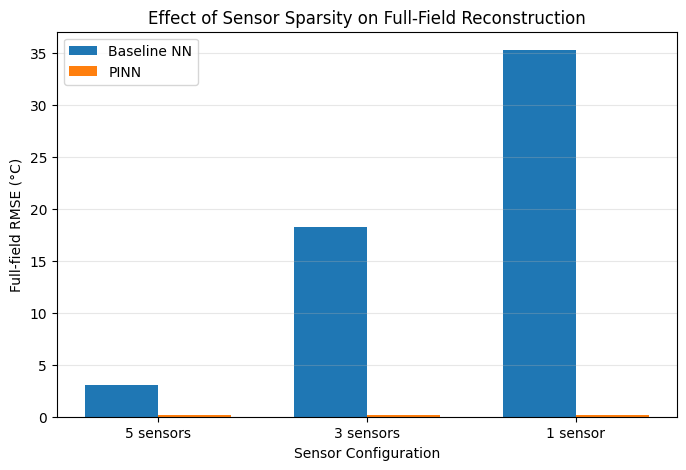

In [45]:
x_positions = np.arange(
    len(comparison_df)
)

width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x_positions - width / 2,
    comparison_df["Baseline_RMSE"],
    width,
    label="Baseline NN"
)

plt.bar(
    x_positions + width / 2,
    comparison_df["PINN_RMSE"],
    width,
    label="PINN"
)

plt.xticks(
    x_positions,
    comparison_df["Configuration"]
)

plt.ylabel("Full-field RMSE (°C)")
plt.xlabel("Sensor Configuration")

plt.title(
    "Effect of Sensor Sparsity on Full-Field Reconstruction"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

### Robustness Interpretation

The data-driven baseline becomes substantially less accurate as the number of available sensors decreases.

Its full-field RMSE increases from approximately:

$$
3.03^\circ C
$$

with five sensors to:

$$
35.26^\circ C
$$

with only one sensor.

In contrast, the PINN maintains a low reconstruction error for all three sensor configurations, with RMSE remaining close to:

$$
0.1^\circ C
$$

even when only one sensor is available.

The small non-monotonic difference between the three-sensor and one-sensor PINN results should not be interpreted as evidence that fewer sensors are beneficial. Training involves stochastic initialization, collocation sampling, and optimization, which can produce small variations between individual runs.

More importantly, the PINN in this experiment is supplied with the correct governing equation, thermal diffusivity, boundary conditions, and initial condition. These physical constraints strongly determine the thermal evolution, reducing the model's dependence on sensor measurements.

The experiment therefore demonstrates that accurate physical knowledge can substantially improve robustness when measurement information becomes sparse.